<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/06_storm_evolution_synthesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 6: สังเคราะห์ตัวชี้วัดทั้งวัน — วงจรชีวิตของพายุฤดูร้อน 3 พ.ค. 2567
### Whole-day synthesis: hail, outflow, turbulence and KDP indicators, daily swaths, site dossiers and lag analysis

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 1–5

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **รวมตัวชี้วัดจาก NB2–NB5** (ลูกเห็บ, outflow, EDR, KDP) เป็นอนุกรมเวลาทั้งวัน (92 volume) และอธิบายวงจรชีวิตของพายุ
2. **สร้างแผนที่ swath รายวัน** (ค่าสูงสุด/ระยะเวลา) และเทียบกับจุดรายงานความเสียหาย
3. **จัดทำ "แฟ้มพายุ" (storm dossier)** ของแต่ละพื้นที่ที่ได้รับผลกระทบ
4. **ส่งออกผลเป็นข้อมูล GIS** (GeoTIFF, GeoPackage) เพื่อใช้ต่อใน QGIS/ArcGIS
5. **วิเคราะห์ความสัมพันธ์และเวลานำ (lag)** ระหว่างตัวชี้วัด อย่างระมัดระวังทางสถิติ

## 📖 1. แนวคิดและสมการ

### 1.1 วงจรชีวิตของพายุฟ้าคะนอง (Byers & Braham, 1949)
| ระยะ | ลักษณะ | สัญญาณเรดาร์ที่คาดหวัง |
|---|---|---|
| **Cumulus / developing** | updraft เด่น | Z เพิ่ม, แกน Z ยกสูง, graupel/IH เหนือ 0 °C |
| **Mature** | ทั้ง updraft + downdraft, ฝนตกหนัก | ลูกเห็บสูงสุด, KDP สูง, EDR สูง, **outflow/downburst** เริ่ม |
| **Dissipating** | downdraft เด่น | Z ลด, สัดส่วนน้ำแข็ง (AG, VI) และ stratiform เพิ่ม |
ลำดับที่คาดหวัง: **ลูกเห็บ/graupel ในระดับบน → ตกลงมา (MH) → downdraft → outflow ที่พื้น** จึงอาจมี "เวลานำ" ระหว่างตัวชี้วัด

### 1.2 ตัวชี้วัดราย volume (ไฟล์ `data/derived/KKN_20240503_volume_metrics.csv`)
| คอลัมน์ | ความหมาย | NB |
|---|---|---|
| `area_Z40_km2`, `area_Z50_km2` | พื้นที่ Z ≥ 40/50 dBZ (0.48°, แก้ attenuation แล้ว, ≤ 200 km) | 4 |
| `area_hail_km2` | พื้นที่ที่คอลัมน์มี MH หรือ IH/HDG **และ** Z ≥ 40 dBZ | 5 |
| `area_graupel_km2` | พื้นที่ที่คอลัมน์มี RP | 5 |
| `vel_abs_p99`, `div_p99`, `azshear_p99` | เปอร์เซ็นไทล์ 99 ของ \|V\|, divergence, \|az. shear\| ใน echo ≥ 20 dBZ | 2 |
| `edr_p95` | เปอร์เซ็นไทล์ 95 ของ EDR$^{1/3}$ | 3 |
| `area_kdp1_km2` | พื้นที่ KDP ≥ 1 °/km (ค่าสูงสุดในคอลัมน์) | 4 |
| `<Site>_*` | ค่าสูงสุดในรัศมี 15 km รอบจุดอ้างอิง | 2–5 |

### 1.3 Swath และระยะเวลา
$$ \mathrm{Swath}_{max}(x, y) = \max_t F(x, y, t),\qquad \mathrm{Duration}(x, y) = \Delta t \sum_t \mathbb{1}[\mathrm{hail}(x, y, t)],\quad \Delta t = 15\ \mathrm{min} $$

### 1.4 ความสัมพันธ์และ lag
Spearman's $\rho$ (ใช้อันดับ จึงทนต่อค่าผิดปกติ) และ cross-correlation ที่เลื่อนเวลา $k$ ขั้น
$$ \rho(k) = \mathrm{corr}_{\mathrm{rank}}\big(X_t,\ Y_{t+k}\big),\qquad k = -4,\dots,4\ (\pm 60\ \mathrm{min}) $$
⚠️ อนุกรมเวลามี **autocorrelation** → จำนวนตัวอย่างที่เป็นอิสระน้อยกว่าจำนวน volume มาก ค่า p-value แบบปกติจึง "มองโลกในแง่ดี" เกินไป

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    !pip install -q --no-build-isolation git+https://github.com/nasa/PyTDA.git
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.8/14.8 MB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 95.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 93.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 424.4/424.4 kB 24.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.7/221.7 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.8/157.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 59.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.6/102.6 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 54.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently

In [2]:
DER = os.path.join(DATA, "derived")
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
radar0 = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar0)
reports = kt.load_reports(DATA, meta)
SITES = {n: (float(kt.site(reports, n)["lon"]), float(kt.site(reports, n)["lat"])) for n in kt.KEY_SITES}

### 2.1 (ไม่บังคับ) คำนวณตัวชี้วัดทั้งวันใหม่
ไฟล์ใน `data/derived/` คำนวณไว้ล่วงหน้าด้วย `pt.run_whole_day()` (ขั้นตอนเดียวกับ NB2–NB5 ทุก volume)
ถ้าต้องการคำนวณใหม่ (เช่น เปลี่ยนพารามิเตอร์) ให้ตั้ง `RUN_FULL = True` — ใช้เวลา **~15–25 นาทีใน Colab**

In [3]:
RUN_FULL = False            # ← เปลี่ยนเป็น True เพื่อคำนวณใหม่ทั้งหมด (92 volume)
if RUN_FULL:
    DER = os.path.join(ROOT, "output", "derived_rerun")
    tab, S, gmeta = pt.run_whole_day(DATA, DER, sites=SITES)

In [4]:
met = pd.read_csv(os.path.join(DER, "KKN_20240503_volume_metrics.csv"), parse_dates=["time_utc"]).set_index("time_utc")
full_index = pd.date_range(met.index[0].normalize(), periods=96, freq="15min")
met = met.reindex(full_index)                          # ช่วงที่ไม่มีข้อมูล (04:00–04:45 UTC) = NaN
S, gmeta = pt.load_swaths(os.path.join(DER, "KKN_20240503_swaths.nc"))
print(f"ตัวชี้วัด: {met.notna().any(axis=1).sum()} volume × {met.shape[1]} คอลัมน์ | swath: {list(S)}")
show = met[["Z_max", "area_Z40_km2", "area_hail_km2", "area_graupel_km2", "vel_abs_p99", "div_p99", "edr_p95", "area_kdp1_km2"]].copy()
show["div_p99"] *= 1e3                                  # → 10⁻³ s⁻¹
show.rename(columns={"div_p99": "div_p99 (1e-3/s)"}).describe().round(2)

ตัวชี้วัด: 92 volume × 53 คอลัมน์ | swath: ['Z_max', 'hail_count', 'graupel_count', 'vel_abs_max', 'div_max', 'azshear_max', 'edr_max', 'kdp_max', 'zdr_max', 'Z_max_time']


,Z_max,area_Z40_km2,area_hail_km2,area_graupel_km2,vel_abs_p99,div_p99 (1e-3/s),edr_p95,area_kdp1_km2
count,92.00,92.00,92.00,92.00,74.00,72.00,77.00,92.00
mean,45.16,165.83,190.43,401.75,10.72,1.75,0.19,260.21
std,10.28,173.48,220.12,365.08,3.23,0.82,0.02,304.86
min,10.50,0.00,0.00,0.00,5.34,0.35,0.13,0.00
25%,45.48,13.00,9.00,51.75,8.87,1.19,0.18,0.00
50%,48.83,108.00,98.00,318.50,10.56,1.58,0.18,147.00
75%,51.93,259.00,332.25,671.00,12.16,2.16,0.19,481.00
max,58.43,579.00,845.00,1220.00,21.98,5.30,0.26,1200.00


## 📈 3. อนุกรมเวลาทั้งวัน: วงจรชีวิตของพายุ

บันทึกรูปแล้ว: figures/nb6_daily_timeseries.png, figures/nb6_daily_timeseries.pdf


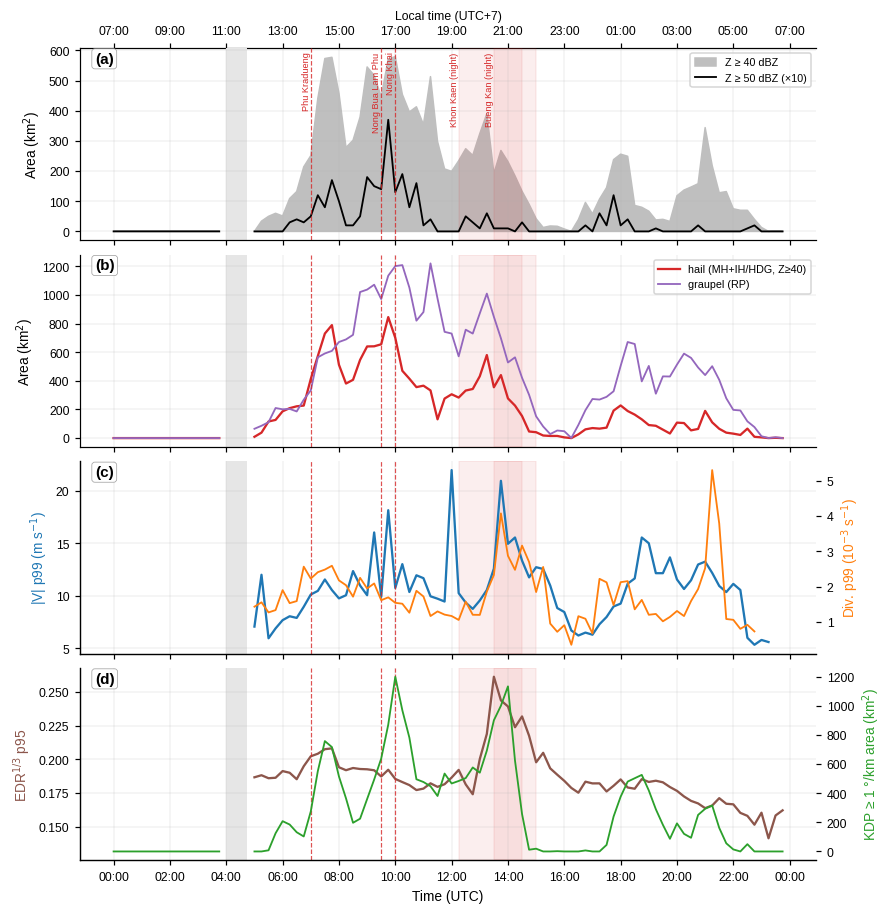

In [5]:
EVENTS = [("Phu Kradueng", "07:00", "07:00"), ("Nong Bua Lam Phu", "09:30", "09:30"), ("Nong Khai", "10:00", "10:00"),
          ("Khon Kaen (night)", "12:15", "15:00"), ("Bueng Kan (night)", "13:30", "14:30")]
d0 = full_index[0]
def tt(hhmm):
    return d0 + pd.Timedelta(hours=int(hhmm[:2]), minutes=int(hhmm[3:]))

fig, axs = plt.subplots(4, 1, figsize=(8, 8.2), sharex=True, layout="constrained")
axs[0].fill_between(met.index, met["area_Z40_km2"], color="0.75", label="Z ≥ 40 dBZ")
axs[0].plot(met.index, met["area_Z50_km2"] * 10, color="k", lw=1.2, label="Z ≥ 50 dBZ (×10)")
axs[0].set_ylabel("Area (km$^2$)")
axs[1].plot(met.index, met["area_hail_km2"], color="tab:red", lw=1.5, label="hail (MH+IH/HDG, Z≥40)")
axs[1].plot(met.index, met["area_graupel_km2"], color="tab:purple", lw=1.2, label="graupel (RP)")
axs[1].set_ylabel("Area (km$^2$)")
axs[2].plot(met.index, met["vel_abs_p99"], color="tab:blue", lw=1.5, label="|V| p99 (m s$^{-1}$)")
ax2b = axs[2].twinx()
ax2b.plot(met.index, met["div_p99"] * 1e3, color="tab:orange", lw=1.2, label="divergence p99")
ax2b.set_ylabel("Div. p99 (10$^{-3}$ s$^{-1}$)", color="tab:orange")
axs[2].set_ylabel("|V| p99 (m s$^{-1}$)", color="tab:blue")
axs[3].plot(met.index, met["edr_p95"], color="tab:brown", lw=1.5, label="EDR$^{1/3}$ p95")
ax3b = axs[3].twinx()
ax3b.plot(met.index, met["area_kdp1_km2"], color="tab:green", lw=1.2, label="KDP ≥ 1 area")
ax3b.set_ylabel("KDP ≥ 1 °/km area (km$^2$)", color="tab:green")
axs[3].set_ylabel("EDR$^{1/3}$ p95", color="tab:brown")
for ax in axs:
    for name, a, b in EVENTS:
        if a == b:
            ax.axvline(tt(a), color="tab:red", ls="--", lw=0.8, alpha=0.8)
        else:
            ax.axvspan(tt(a), tt(b), color="tab:red", alpha=0.08)
    ax.axvspan(tt("04:00"), tt("04:45"), color="0.9", hatch="//", lw=0)
    ax.grid(lw=0.3, alpha=0.5)
for name, a, b in EVENTS:
    axs[0].text(tt(a), axs[0].get_ylim()[1] * 0.98, name, rotation=90, fontsize=6, va="top", ha="right", color="tab:red")
axs[0].legend(fontsize=7, loc="upper right"); axs[1].legend(fontsize=7, loc="upper right")
mp.time_axis(axs[0], interval_h=2)
mp.time_axis(axs[3], interval_h=2, local_top=False)
axs[0].set_xlabel(""); axs[0].tick_params(labelbottom=False)
mp.panel_labels(axs)
mp.save_figure(fig, "nb6_daily_timeseries")
plt.show()

**อ่านกราฟ** (เส้นประแดง = เวลารายงาน, แถบแดงจาง = ช่วงรายงานกลางคืน, ลายขีด = ไม่มีข้อมูล):
- (a) พายุเริ่ม **ราว 05:00 UTC (12:00 น.)** บนพื้นที่สูงด้านตะวันตก พื้นที่ Z ≥ 40 dBZ เพิ่มเร็วถึงจุดสูงสุดช่วง 07:30–10:00 UTC และมีรอบที่สองช่วงค่ำ–กลางคืน
- (b) พื้นที่ลูกเห็บและ graupel **ขึ้นลงตามพื้นที่แกนพายุ** และสูงในช่วงที่มีรายงานที่ภูกระดึง–หนองบัวลำภู–หนองคาย
- (c) |V| p99 สูงเป็นช่วง ๆ เช่น ~09:30 UTC (นากลาง) และ ~12:00 กับ ~13:45 UTC (พายุกลางคืนเข้าใกล้ขอนแก่น) — ช่วงหลังพายุอยู่ใกล้เรดาร์ ลำคลื่นต่ำ จึงเห็นลมใกล้พื้นได้ดีกว่าช่วงบ่ายที่พายุอยู่ไกล
  (ตัวชี้วัด Doppler จึง **ขึ้นกับระยะของพายุจากเรดาร์** ไม่ได้สะท้อนความแรงอย่างเดียว)
- (d) พื้นที่ KDP ≥ 1 °/km (ฝนหนัก/น้ำเหลวมาก) สูงสุด ~10:00 และ ~14:00 UTC ขณะที่ EDR p95 สูงสุดช่วงพายุกลางคืนเหนือขอนแก่น — สองตัวชี้วัดนี้บอก "ความเข้ม" คนละมิติ

## 🗺️ 4. แผนที่ swath รายวัน

บันทึกรูปแล้ว: figures/nb6_daily_swaths.png, figures/nb6_daily_swaths.pdf


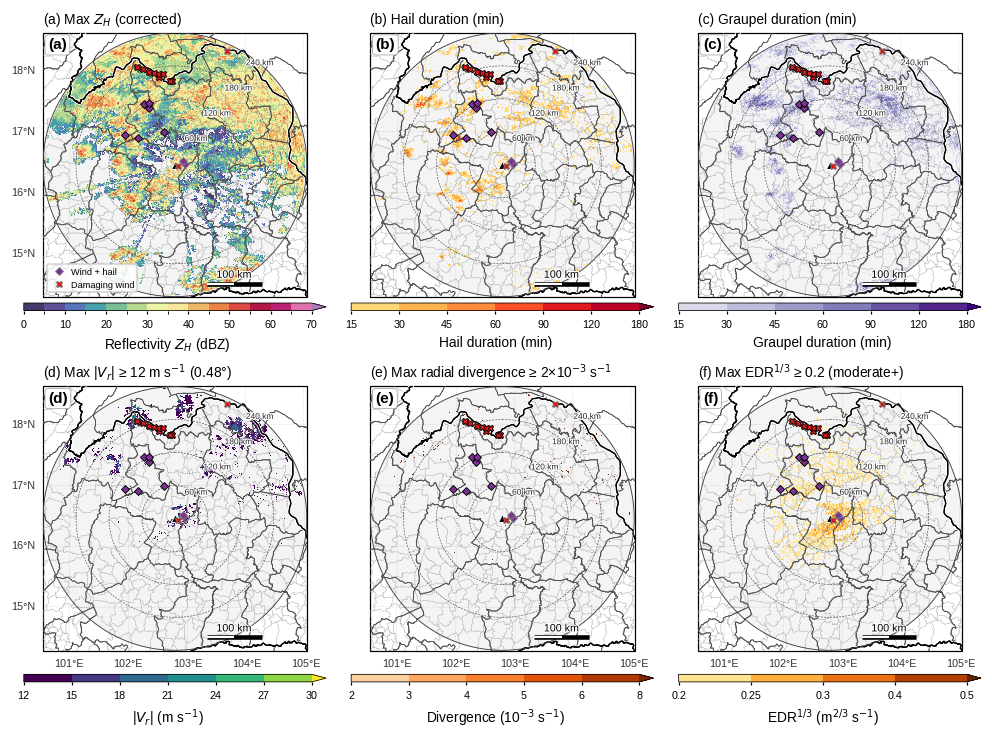

In [6]:
H_DUR = S["hail_count"] * 15.0                         # นาทีที่มีลูกเห็บ
G_DUR = S["graupel_count"] * 15.0
import matplotlib as mpl
def strong(name, lo=0.25):
    """ตัดส่วนสีอ่อนของ colormap ทิ้ง เพื่อให้ค่าระดับแรกมองเห็นชัด"""
    return mpl.colors.ListedColormap(mpl.colormaps[name](np.linspace(lo, 1, 256)))
panels = [
    (S["Z_max"], "Z", None, "(a) Max $Z_H$ (corrected)", None),
    (H_DUR, strong("YlOrRd"), [15, 30, 45, 60, 90, 120, 180], "(b) Hail duration (min)", "Hail duration (min)"),
    (G_DUR, strong("Purples"), [15, 30, 45, 60, 90, 120, 180], "(c) Graupel duration (min)", "Graupel duration (min)"),
    (S["vel_abs_max"], strong("viridis", 0.0), [12, 15, 18, 21, 24, 27, 30], "(d) Max |$V_r$| ≥ 12 m s$^{-1}$ (0.48°)", "|$V_r$| (m s$^{-1}$)"),
    (S["div_max"] * 1e3, strong("Oranges"), [2, 3, 4, 5, 6, 8], "(e) Max radial divergence ≥ 2×10$^{-3}$ s$^{-1}$", "Divergence (10$^{-3}$ s$^{-1}$)"),
    (S["edr_max"], strong("YlOrBr"), [0.2, 0.25, 0.3, 0.4, 0.5], "(f) Max EDR$^{1/3}$ ≥ 0.2 (moderate+)", "EDR$^{1/3}$ (m$^{2/3}$ s$^{-1}$)"),
]
fig, axs = mp.map_panels(2, 3, gmeta, panel_width=3.0)
for k, (ax, (fld, cm, lv, ttl, lab)) in enumerate(zip(axs, panels)):
    gl = (("left",) if k % 3 == 0 else ()) + (("bottom",) if k >= 3 else ())
    if cm == "Z":
        im = mp.radar_map(ax, fld, gmeta, title=ttl, gridline_labels=gl, north=(k == 2))
    else:
        fld = np.where(fld >= lv[0], fld, np.nan)          # แสดงเฉพาะค่าที่ถึงระดับแรก
        im = mp.field_map(ax, fld, gmeta, cmap=cm, levels=lv, label=lab, title=ttl, gridline_labels=gl, extend="max")
    mp.add_reports(ax, reports, legend=(k == 0), ms=4)
    mp.add_colorbar(fig, im, ax, shrink=0.95, extend="max")
mp.panel_labels(axs)
mp.save_figure(fig, "nb6_daily_swaths")
plt.show()

- (a) แนว Z สูงพาดจาก **ตะวันตกเฉียงใต้ (เลย/ภูกระดึง) ไปตะวันออกเฉียงเหนือ (หนองคาย/บึงกาฬ)** ตามทิศการเคลื่อนที่ของพายุ (ENE) ที่ศึกษาใน repo pysteps
- (b) **ระยะเวลาลูกเห็บ** ส่วนใหญ่ 15–30 นาที (1–2 volume) และมีจุดที่ ≥ 60 นาทีเป็นหย่อมเล็ก ๆ — ข้อมูลนี้ใช้ทำ **แผนที่เสี่ยงลูกเห็บ** ต่อพืชผลได้
  (คลาส IH/HDG รวม graupel ความหนาแน่นสูงที่อยู่บนฟ้าด้วย พื้นที่จึงกว้างกว่าลูกเห็บที่ตกถึงพื้นจริง)
- (d)–(e) ความเร็ว/divergence สูงที่ระยะไกลอาจมาจากลมระดับกลาง (ลำคลื่นสูง) ไม่ใช่ลมที่พื้น — ต้องแปลผลร่วมกับความสูงลำคลื่น (NB1)
- (f) EDR สูงกระจุกใกล้เรดาร์ (พายุกลางคืนเหนือขอนแก่น) — แต่ที่ระยะ < 30 km ปริมาตรวัดเล็กและมี clutter ได้ง่าย ควรตรวจสอบก่อนสรุปว่าเป็นความปั่นป่วนรุนแรง

## 🗂️ 5. แฟ้มพายุ (storm dossier) ของแต่ละพื้นที่

In [7]:
rows = []
date0 = d0.to_pydatetime()
for name in kt.KEY_SITES:
    key = name.replace(" ", "_")
    s_ = kt.site(reports, name)
    z = met[f"{key}_Zmax"]
    tr = kt.report_time_utc(s_, date0)
    row = {"site": name, "range_km": round(float(s_["range_km"])),
           "report_UTC": tr.strftime("%H:%M") if tr else "night",
           "Zmax": z.max(), "t_Zmax": z.idxmax().strftime("%H:%M") if z.notna().any() else "—",
           "hail_km2_max": met[f"{key}_hail_km2"].max(),
           "hail_minutes": int((met[f"{key}_hail_km2"] > 0).sum() * 15),
           "Vmax": met[f"{key}_velmax"].max(), "DIVmax_1e-3": met[f"{key}_divmax"].max() * 1e3,
           "EDRmax": met[f"{key}_edrmax"].max()}
    hk = met[f"{key}_hail_km2"]
    row["t_hail_max"] = hk.idxmax().strftime("%H:%M") if hk.max() > 0 else "—"
    rows.append(row)
dossier = pd.DataFrame(rows).set_index("site")
dossier.round(2)

,range_km,report_UTC,Zmax,t_Zmax,hail_km2_max,hail_minutes,Vmax,DIVmax_1e-3,EDRmax,t_hail_max
site,,,,,,,,,,
Phu Kradueng,105,07:00,53.16,07:15,191.0,150,13.86,5.45,0.25,07:30
Na Klang,114,09:30,54.24,09:45,134.0,180,17.06,2.54,0.23,09:45
Suwannakhuha,121,09:30,54.24,09:45,178.0,120,17.06,2.37,0.23,10:00
Si Chiang Mai,162,10:00,49.22,11:15,218.0,75,12.36,2.01,0.21,11:00
Bueng Kan,228,night,49.03,13:45,77.0,75,10.96,1.21,0.14,14:00
Khon Kaen city,6,night,53.50,13:45,100.0,150,27.02,8.44,0.91,13:45


- จุดที่มีรายงานลูกเห็บ (ภูกระดึง, นากลาง, สุวรรณคูหา, ขอนแก่น) ส่วนใหญ่มี **ระยะเวลาลูกเห็บจาก HID > 0** และ Z สูงสุด ≥ 50 dBZ
- **ศรีเชียงใหม่ (~160 km)** และ **บึงกาฬ (~230 km)**: ลำคลื่นต่ำสุดสูง 3–5 km → Doppler ไม่เห็นลมใกล้พื้น ค่า V/DIV ต่ำกว่าความรุนแรงจริง
- **ขอนแก่น (กลางคืน)** อยู่ใกล้เรดาร์มาก (< 20 km) — ลำคลื่นเห็นลมใกล้พื้นได้ดี (V และ divergence สูงสุดของทั้งตาราง) เวลาของค่าสูงสุดช่วยระบุ "เวลาเกิดเหตุ" ที่ข่าวไม่ได้บอก
  แต่ EDR ที่สูงมากใกล้เรดาร์ต้องระวัง clutter และผลของปริมาตรวัดขนาดเล็ก
- ตารางนี้คือ **หลักฐานเชิงปริมาณ** สำหรับรายงานภัยพิบัติหรือบทความวิจัย

## 💾 6. ส่งออกเป็นข้อมูล GIS (GeoTIFF + GeoPackage)

In [8]:
from utils import data_io as dio
os.makedirs("output", exist_ok=True)
bands = [S["Z_max"], H_DUR, G_DUR, S["vel_abs_max"], S["div_max"] * 1e3, S["edr_max"], S["kdp_max"]]
names = ["Zmax_dBZ", "hail_duration_min", "graupel_duration_min", "Vabs_max_ms", "div_max_1e-3s", "EDR_max", "KDP_max"]
tif = dio.save_geotiff("output/KKN_20240503_daily_swaths.tif", bands, gmeta, names)
print("GeoTIFF:", tif)

import geopandas as gpd
import rasterio.features
from rasterio.transform import from_origin
from shapely.geometry import shape
trf = from_origin(gmeta["x1"], gmeta["y2"], gmeta["xpixelsize"], gmeta["ypixelsize"])
cls = np.digitize(np.nan_to_num(H_DUR), [15, 30, 60]).astype("int16")          # 1: 15–29, 2: 30–59, 3: ≥60 นาที
polys = [{"geometry": shape(g), "hail_class": int(v)} for g, v in rasterio.features.shapes(cls, mask=cls > 0, transform=trf)]
hail_gdf = gpd.GeoDataFrame(polys, crs=gmeta["projection"])
hail_gdf["label"] = hail_gdf["hail_class"].map({1: "15–29 min", 2: "30–59 min", 3: "≥ 60 min"})
hail_gdf["area_km2"] = hail_gdf.area / 1e6
hail_gdf = hail_gdf.to_crs("EPSG:4326")
hail_gdf.to_file("output/KKN_20240503_hail_duration.gpkg", layer="hail_duration", driver="GPKG")
print(hail_gdf.groupby("label")["area_km2"].agg(["count", "sum"]).round(0))

GeoTIFF: output/KKN_20240503_daily_swaths.tif
           count      sum
label                    
15–29 min   1976  12731.0
30–59 min    526   3250.0
≥ 60 min      45    128.0


เปิดไฟล์ทั้งสองใน **QGIS** ได้ทันที (ระบบพิกัด AEQD ของเรดาร์สำหรับ GeoTIFF และ WGS84 สำหรับ GeoPackage) — ใช้ซ้อนกับขอบเขตตำบล พื้นที่เกษตร หรือข้อมูลประชากร เพื่อประเมินผลกระทบ

## 🔗 7. ความสัมพันธ์ระหว่างตัวชี้วัด (ช่วงพายุ 05:00–16:00 UTC)

บันทึกรูปแล้ว: figures/nb6_correlation_matrix.png, figures/nb6_correlation_matrix.pdf


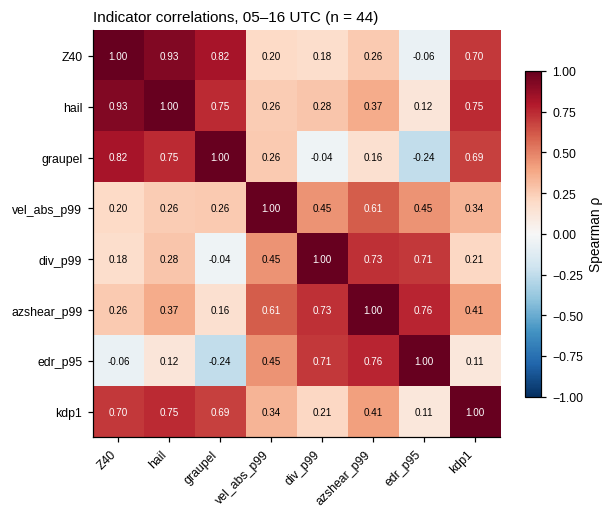

In [9]:
from scipy.stats import spearmanr
IND = ["area_Z40_km2", "area_hail_km2", "area_graupel_km2", "vel_abs_p99", "div_p99", "azshear_p99", "edr_p95", "area_kdp1_km2"]
storm = met.loc[tt("05:00"):tt("16:00"), IND].dropna()
rho, p = spearmanr(storm.values)
rho = pd.DataFrame(rho, index=IND, columns=IND)
fig, ax = plt.subplots(figsize=(5.6, 4.6), layout="constrained")
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(IND)), [c.replace("_km2", "").replace("area_", "") for c in IND], rotation=45, ha="right")
ax.set_yticks(range(len(IND)), [c.replace("_km2", "").replace("area_", "") for c in IND])
for i in range(len(IND)):
    for j in range(len(IND)):
        ax.text(j, i, f"{rho.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="w" if abs(rho.iloc[i, j]) > 0.6 else "k")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title(f"Indicator correlations, 05–16 UTC (n = {len(storm)})", loc="left")
mp.save_figure(fig, "nb6_correlation_matrix")
plt.show()

- ตัวชี้วัดที่เกี่ยวกับ **ขนาดของพายุ** (พื้นที่ Z40, ลูกเห็บ, graupel, KDP) สัมพันธ์กันสูง — เพราะพายุใหญ่ก็มีทุกอย่างมากขึ้น (*size effect*)
- ตัวชี้วัดจาก Doppler (|V|, divergence, shear) สัมพันธ์กับตัวชี้วัดขนาดน้อยกว่า → ให้ **ข้อมูลใหม่** ที่ reflectivity ไม่มี
- ⚠️ correlation สูงไม่ได้แปลว่าเป็นเหตุ–ผล และ n ที่แท้จริงน้อยกว่าที่เห็น (autocorrelation)

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 6.1: ลูกเห็บนำหน้าลม outflow หรือไม่?
คำนวณ lagged Spearman correlation ระหว่าง `area_hail_km2` (X) กับ `div_p99` และ `vel_abs_p99` (Y) ที่ $k = -4 \dots +4$ (×15 นาที) ในช่วง 05:00–16:00 UTC
($k > 0$ หมายถึง Y เกิดตามหลัง X) แล้วพลอต $\rho(k)$

**คำถาม:** lag ที่ให้ ρ สูงสุดคือเท่าไร? สอดคล้องกับแนวคิด "ลูกเห็บ/การละลาย → downdraft → outflow" หรือไม่? ผลนี้น่าเชื่อถือแค่ไหน?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `x = met.loc[a:b, "area_hail_km2"]`, `y = met["div_p99"].shift(-k).loc[a:b]` (shift(−k) = ดึงค่าในอนาคตมาเทียบ)
- ตัดค่า NaN ก่อน: `ok = x.notna() & y.notna()` แล้ว `spearmanr(x[ok], y[ok])[0]`

</details>

In [10]:
# ✍️ แบบฝึกหัด 6.1 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb6_ex61_lag.png, figures/nb6_ex61_lag.pdf


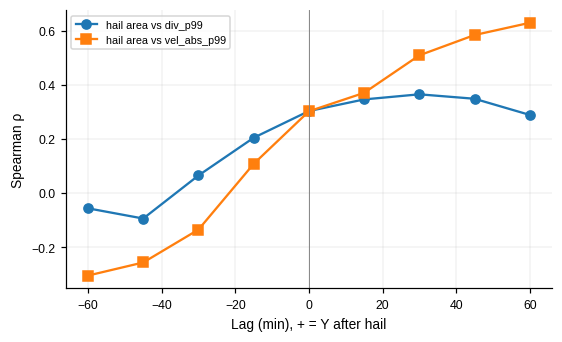

lag_min       -60   -45   -30   -15   0     15    30    45    60
div_p99     -0.06 -0.09  0.07  0.20  0.3  0.35  0.36  0.35  0.29
vel_abs_p99 -0.30 -0.26 -0.13  0.11  0.3  0.37  0.51  0.58  0.63
→ div_p99: ρ สูงสุด 0.36 ที่ lag +30 นาที
→ vel_abs_p99: ρ สูงสุด 0.63 ที่ lag +60 นาที (อยู่ที่ขอบหน้าต่าง → ไม่มีจุดสูงสุดชัด อาจเป็นแนวโน้มระยะยาว เช่น พายุเคลื่อนเข้าใกล้เรดาร์ช่วงค่ำ)
  lag บวก = outflow ตามหลังลูกเห็บ (สอดคล้องกับแนวคิด) แต่ผลรวมทั้งพื้นที่ปนหลายเซลล์ที่อยู่ในระยะต่างกัน
  และความละเอียดเวลา 15 นาทีหยาบกว่าอายุของ downburst (5–15 นาที) → ควรวิเคราะห์ระดับเซลล์ (cell tracking) ก่อนสรุป


In [11]:
#@title ✅ เฉลยแบบฝึกหัด 6.1
a, b = tt("05:00"), tt("16:00")
lags = range(-4, 5)
res = {}
for ycol in ("div_p99", "vel_abs_p99"):
    vals = []
    for k in lags:
        x = met.loc[a:b, "area_hail_km2"]
        y = met[ycol].shift(-k).loc[a:b]
        ok = x.notna() & y.notna()
        vals.append(spearmanr(x[ok], y[ok])[0])
    res[ycol] = vals
lag_df = pd.DataFrame(res, index=[k * 15 for k in lags]); lag_df.index.name = "lag_min"
fig, ax = plt.subplots(figsize=(5, 3), layout="constrained")
for c, mk in zip(lag_df.columns, ("o", "s")):
    ax.plot(lag_df.index, lag_df[c], marker=mk, label=f"hail area vs {c}")
ax.axvline(0, color="0.5", lw=0.6); ax.set_xlabel("Lag (min), + = Y after hail"); ax.set_ylabel("Spearman ρ")
ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb6_ex61_lag")
plt.show()
print(lag_df.round(2).T)
for c in lag_df.columns:
    kbest = lag_df[c].idxmax()
    note = " (อยู่ที่ขอบหน้าต่าง → ไม่มีจุดสูงสุดชัด อาจเป็นแนวโน้มระยะยาว เช่น พายุเคลื่อนเข้าใกล้เรดาร์ช่วงค่ำ)" if abs(kbest) == 60 else ""
    print(f"→ {c}: ρ สูงสุด {lag_df[c].max():.2f} ที่ lag {kbest:+d} นาที{note}")
print("  lag บวก = outflow ตามหลังลูกเห็บ (สอดคล้องกับแนวคิด) แต่ผลรวมทั้งพื้นที่ปนหลายเซลล์ที่อยู่ในระยะต่างกัน"
      "\n  และความละเอียดเวลา 15 นาทีหยาบกว่าอายุของ downburst (5–15 นาที) → ควรวิเคราะห์ระดับเซลล์ (cell tracking) ก่อนสรุป")

### 🧪 แบบฝึกหัด 6.2: swath แบบไหน "ชี้" จุดเกิดเหตุได้ดีที่สุด?
สำหรับทุกจุดใน `reports` หา **ค่าสูงสุดของแต่ละ swath ในรัศมี 5 km** แล้วแปลงเป็น **เปอร์เซ็นไทล์** เทียบกับ pixel ทั้งหมดที่มี echo (Z_max ≥ 20 dBZ)
ค่าเฉลี่ยเปอร์เซ็นไทล์ที่สูง = swath นั้นมีค่าสูงที่จุดเกิดเหตุมากกว่าพื้นที่ทั่วไป

**คำถาม:** swath ไหนแยกจุดเกิดเหตุได้ดีที่สุด? ผลต่างกันระหว่างรายงาน "ลมแรง" กับ "ลมแรง + ลูกเห็บ" หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ระยะ pixel ถึงจุด: `X, Y = np.meshgrid(gmeta["x"], gmeta["y"])` แล้ว `np.hypot(X - r.x, Y - r.y) <= 5000`
- เปอร์เซ็นไทล์: `scipy.stats.percentileofscore(background_values, v)`

</details>

In [12]:
# ✍️ แบบฝึกหัด 6.2 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 6.2
from scipy.stats import percentileofscore
X, Y = np.meshgrid(gmeta["x"], gmeta["y"])
echo = S["Z_max"] >= 20
fields = {"Z_max": S["Z_max"], "hail_duration": H_DUR, "graupel_duration": G_DUR, "Vabs_max": S["vel_abs_max"],
          "div_max": S["div_max"], "edr_max": S["edr_max"], "kdp_max": S["kdp_max"]}
rows = []
for _, r in reports.iterrows():
    near = np.hypot(X - r["x"], Y - r["y"]) <= 5000
    row = {"id": r["id"], "district": r["district"], "hail": "ลูกเห็บ" in r["hazard"]}
    for k, F_ in fields.items():
        bg = F_[echo & np.isfinite(F_)]
        v = np.nanmax(np.where(near, F_, np.nan)) if np.isfinite(np.where(near, F_, np.nan)).any() else np.nan
        row[k] = percentileofscore(bg, v) if np.isfinite(v) else np.nan
    rows.append(row)
pr = pd.DataFrame(rows)
summary = pd.DataFrame({"all reports": pr[list(fields)].mean(), "wind+hail": pr.loc[pr.hail, list(fields)].mean(),
                        "wind only": pr.loc[~pr.hail, list(fields)].mean()}).round(0)
print("ค่าเฉลี่ยเปอร์เซ็นไทล์ของ swath ที่จุดรายงาน (50 = เหมือนพื้นที่ทั่วไป)")
print(summary.sort_values("all reports", ascending=False))
best = summary["all reports"].idxmax()
print(f"\n→ swath ที่แยกจุดเกิดเหตุได้ดีที่สุดโดยรวม: {best}")
print("  จุด 'ลมแรง' ที่หนองคาย/บึงกาฬอยู่ไกล → ลำคลื่นสูง ตัวชี้วัด Doppler ใกล้พื้นจึงด้อยกว่า ; ตำแหน่งในข่าวเป็นระดับตำบล ไม่ใช่พิกัดเกิดเหตุจริง"
      "\n  งานวิจัยจริงควรใช้ ROC/AUC กับชุดข้อมูลหลายพายุ และระวัง 'reporting bias' (รายงานมากในที่มีคนอยู่มาก)")

ค่าเฉลี่ยเปอร์เซ็นไทล์ของ swath ที่จุดรายงาน (50 = เหมือนพื้นที่ทั่วไป)
                  all reports  wind+hail  wind only
Z_max                    95.0       94.0       95.0
kdp_max                  95.0       96.0       94.0
hail_duration            92.0       97.0       88.0
edr_max                  92.0       97.0       88.0
Vabs_max                 85.0       87.0       83.0
graupel_duration         81.0       72.0       87.0
div_max                  55.0       56.0       54.0

→ swath ที่แยกจุดเกิดเหตุได้ดีที่สุดโดยรวม: Z_max
  จุด 'ลมแรง' ที่หนองคาย/บึงกาฬอยู่ไกล → ลำคลื่นสูง ตัวชี้วัด Doppler ใกล้พื้นจึงด้อยกว่า ; ตำแหน่งในข่าวเป็นระดับตำบล ไม่ใช่พิกัดเกิดเหตุจริง
  งานวิจัยจริงควรใช้ ROC/AUC กับชุดข้อมูลหลายพายุ และระวัง 'reporting bias' (รายงานมากในที่มีคนอยู่มาก)


### 🧪 แบบฝึกหัด 6.3: ความสัมพันธ์ที่ "มีนัยสำคัญ" จริงหรือ?
1. หาค่า Spearman ρ และ p-value ระหว่าง `area_hail_km2` กับ (ก) `area_kdp1_km2` และ (ข) `edr_p95` ในช่วง 05:00–16:00 UTC
2. ประมาณ **จำนวนตัวอย่างที่เป็นอิสระ** $n_{eff} \approx n\,\frac{1 - r_1 r_2}{1 + r_1 r_2}$ (Bretherton et al., 1999) โดย $r_1, r_2$ = lag-1 autocorrelation ของแต่ละตัวแปร
3. คำนวณ p-value ใหม่ด้วย $n_{eff}$ (ใช้ $t = \rho\sqrt{(n_{eff}-2)/(1-\rho^2)}$)

**คำถาม:** ข้อสรุปเปลี่ยนไปหรือไม่? บทเรียนสำหรับการเขียนงานวิจัยคืออะไร?

<details>
<summary><b>💡 คำใบ้</b></summary>

- lag-1 autocorrelation: `x.autocorr(lag=1)`
- `from scipy.stats import t as tdist; p = 2 * tdist.sf(abs(t), n_eff - 2)`

</details>

In [14]:
# ✍️ แบบฝึกหัด 6.3 — เขียนโค้ดของคุณที่นี่

In [15]:
#@title ✅ เฉลยแบบฝึกหัด 6.3
from scipy.stats import t as tdist
out = []
for ycol in ("area_kdp1_km2", "edr_p95"):
    d = met.loc[tt("05:00"):tt("16:00"), ["area_hail_km2", ycol]].dropna()
    rho_, p_ = spearmanr(d["area_hail_km2"], d[ycol])
    r1, r2 = d["area_hail_km2"].autocorr(1), d[ycol].autocorr(1)
    n = len(d)
    n_eff = max(n * (1 - r1 * r2) / (1 + r1 * r2), 3)
    t_ = rho_ * np.sqrt((n_eff - 2) / (1 - rho_ ** 2))
    out.append({"pair": f"hail vs {ycol}", "rho": rho_, "n": n, "p_naive": p_, "r1": r1, "r2": r2,
                "n_eff": n_eff, "p_corrected": 2 * tdist.sf(abs(t_), n_eff - 2)})
out = pd.DataFrame(out).set_index("pair")
print(out.round(3))
for pair, r in out.iterrows():
    verdict = ("ยังมีนัยสำคัญ" if r.p_corrected < 0.05 else "ไม่มีนัยสำคัญแล้ว") if r.p_naive < 0.05 else "ไม่มีนัยสำคัญตั้งแต่แรก"
    print(f"→ {pair}: p {r.p_naive:.2g} → {r.p_corrected:.2g} ({verdict})")
print("  n_eff น้อยกว่า n หลายเท่า เพราะค่าแต่ละ 15 นาทีไม่เป็นอิสระต่อกัน → p-value ใหญ่ขึ้นมาก"
      "\n  บทเรียน: รายงาน ρ พร้อมวิธีจัดการ autocorrelation และยืนยันด้วยหลายพายุ/หลายวัน ไม่สรุปจากพายุเดียว")

                         rho   n  p_naive     r1     r2  n_eff  p_corrected
pair                                                                       
hail vs area_kdp1_km2  0.765  45    0.000  0.878  0.867  6.113        0.072
hail vs edr_p95        0.141  45    0.357  0.878  0.834  6.953        0.765
→ hail vs area_kdp1_km2: p 9.7e-10 → 0.072 (ไม่มีนัยสำคัญแล้ว)
→ hail vs edr_p95: p 0.36 → 0.76 (ไม่มีนัยสำคัญตั้งแต่แรก)
  n_eff น้อยกว่า n หลายเท่า เพราะค่าแต่ละ 15 นาทีไม่เป็นอิสระต่อกัน → p-value ใหญ่ขึ้นมาก
  บทเรียน: รายงาน ρ พร้อมวิธีจัดการ autocorrelation และยืนยันด้วยหลายพายุ/หลายวัน ไม่สรุปจากพายุเดียว


---
## 📝 สรุป
- ตัวชี้วัด 92 volume แสดง **วงจรชีวิตของพายุ** ตั้งแต่ก่อตัวบนพื้นที่สูงตอนเที่ยง → ระยะเจริญเต็มที่ช่วงบ่าย (ลูกเห็บ, outflow, EDR สูง) → รอบกลางคืนใกล้ขอนแก่น
- **แผนที่ swath** (ระยะเวลาลูกเห็บ, ความเร็วสูงสุด, divergence, EDR) สรุปผลกระทบทั้งวันในภาพเดียว และส่งออกเป็น GIS ได้
- **แฟ้มพายุ** รายพื้นที่เป็นหลักฐานเชิงปริมาณสำหรับรายงานภัยพิบัติ แต่ต้องระบุข้อจำกัดเรื่องระยะ/ความสูงลำคลื่น
- การวิเคราะห์ความสัมพันธ์และ lag ต้อง **ระวัง size effect และ autocorrelation**

### ❓ คำถามชวนคิด
1. ถ้าจะสร้าง **ดัชนีความรุนแรงของพายุ (storm severity index)** จากตัวชี้วัดใน notebook นี้ จะเลือกตัวแปรใด ถ่วงน้ำหนักอย่างไร และตรวจสอบกับอะไร?
2. รายงานความเสียหายกลางคืน (ขอนแก่น, บึงกาฬ) ไม่มีเวลาแน่นอน — ข้อมูลเรดาร์ช่วย "ระบุเวลาเกิดเหตุ" ได้อย่างไร และมีความไม่แน่นอนเท่าไร?
3. ถ้ามีข้อมูลหลายปี (เช่น พายุฤดูร้อนเดือน มี.ค.–พ.ค. ทุกปี) จะใช้ workflow ของ repo นี้ตอบคำถามภูมิอากาศอะไรได้บ้าง?

**🚀 ต่อยอด (ป.โท / วิทยานิพนธ์):**
- ทำ **cell-based analysis**: ใช้ T-DaTing (repo pysteps NB6) ติดตามเซลล์ แล้วคำนวณตัวชี้วัด HID/Doppler/EDR **รายเซลล์** แทนรายพื้นที่
- สร้าง **ภูมิอากาศวิทยาลูกเห็บของอีสาน** จาก swath หลายพายุ เทียบกับข้อมูลความเสียหายของ ปภ. และพื้นที่เกษตร
- พัฒนา **ระบบเตือนภัย downburst/ลูกเห็บ** ด้วย machine learning โดยใช้ตัวชี้วัดในตาราง derived เป็น features

### 📚 เอกสารอ้างอิง
- Byers, H. R., & Braham, R. R. (1949). *The Thunderstorm*. U.S. Government Printing Office.
- Bretherton, C. S., Widmann, M., Dymnikov, V. P., Wallace, J. M., & Bladé, I. (1999). The effective number of spatial degrees of freedom of a time-varying field. *J. Climate*, 12, 1990–2009.
- Wilks, D. S. (2019). *Statistical Methods in the Atmospheric Sciences* (4th ed.). Elsevier.
- Kumjian, M. R., & Ryzhkov, A. V. (2008). Polarimetric signatures in supercell thunderstorms. *J. Appl. Meteor. Climatol.*, 47, 1940–1961.
- Wakimoto, R. M. (2001). Convectively driven high wind events. In *Severe Convective Storms* (Meteor. Monogr. 28, pp. 255–298). AMS.